In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from numpy import genfromtxt
from matplotlib import cm
from scipy.spatial.distance import cdist
import re
import math
import scipy
from scipy.stats import ks_2samp
from matplotlib.patches import Rectangle
import pathlib
from matplotlib import font_manager
from scipy.stats import fisher_exact
#from soursop.sstrajectory import SSTrajectory
from IPython.display import display, Markdown, HTML
import gseapy as gp
import matplotlib.colors as mcolors

In [2]:
# Setup the fonts
fonts_path = pathlib.Path.home().joinpath('fonts') # i.e. `~/fonts` (update as needed)
font_filename = 'ARIAL.TTF'
font_path = fonts_path.joinpath(font_filename)
print(font_path)

font_manager.fontManager.addfont(str(font_path))
prop = font_manager.FontProperties(fname=font_path)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()
plt.rcParams['pdf.fonttype'] = 42 # Makes text editiable
plt.rcParams['ps.fonttype'] = 42

COLOR_MAP = dict()
COLOR_MAP['A']         = '#8c8c8c'
COLOR_MAP['CHNQST']    = '#077a15'
COLOR_MAP['DE']        = '#e23a36'
COLOR_MAP['FWY']       = '#f58220'
COLOR_MAP['G']         = '#86bd8d'
COLOR_MAP['ILMV']      = '#231f20'
COLOR_MAP['KR']        = '#1725c2'
COLOR_MAP['P']         = '#c25fc9'


# Using the global color map, we convert the colormap of amino acid
# groups, to a map against individual amino acids. This
# serves as our internal color map which is used for styling.
aacolor_map=dict()
for amino_acids in COLOR_MAP:
    for amino_acid in amino_acids:
        aacolor_map[amino_acid] = COLOR_MAP[amino_acids]

/Users/magalhae/fonts/ARIAL.TTF


In [3]:
Imputed_matrix = pd.read_csv("/Users/magalhae/Desktop/FANCY_proteome/FANCY_20250630_Nucleolous_CoOMICS/Test_ActD_SPKL_NUCL/Imputed_matrix.csv", low_memory = False)
Imputed_matrix.columns = [i.replace(" MaxLFQ Intensity", "") for i in Imputed_matrix.columns]

In [4]:
# dual_g = ['Q66PJ3', 'Q8WUA2', 'Q14498', 'Q8WUQ7', 'Q9Y388', 'Q9BUQ8', 'O75400', 'Q9H930', 'Q9BU76', 'Q8WXF0', 'Q6PH81', 'Q14739', 'Q69YQ0', 'Q9BSF8', 'Q9H307', 'Q8N715', 'Q96JP5', 'Q9P013', 'O14646', 'O95218']
# dual_idr_g = ['Q8TF01', 'P30414', 'Q15878', 'Q9H9J4', 'Q66PJ3', 'P55196', 'Q9UPT8', 'Q8WUA2', 'Q9NWH9', 'Q14498', 'Q7Z4V5', 'A0AAG2UXK7', 'Q01831', 'Q96T58', 'Q96JP5', 'Q0ZGT2', 'P49756', 'Q7Z6E9', 'Q5M9Q1', 'Q86YN6', 'Q9NYF8', 'Q8TEW0', 'Q9P013', 'Q9Y6V0', 'O43290', 'Q8WUQ7', 'Q9P1Y6', 'O95819', 'Q04637', 'O15042', 'Q9UQ26', 'O60237', 'P52756', 'Q86X95', 'Q9P2R6', 'A6H8Y1', 'Q92576', 'Q14004', 'Q9Y388', 'Q6UB99', 'Q9UQ35', 'Q9UKV3', 'Q6UN15', 'Q8TDD1', 'Q9NQS7', 'Q12872', 'Q86VM9', 'Q8NEE8', 'Q9GZU2', 'Q9Y520', 'Q9BUQ8', 'P21127', 'Q9UKJ3', 'Q9UQ88', 'Q6KC79', 'Q8WXA9', 'Q9H307', 'Q9Y2W1', 'Q9H1I8', 'O75400', 'Q96N46', 'Q5VUA4', 'Q6ZU35', 'Q9H4L4', 'Q5JTH9', 'Q9BXP5', 'Q8N5F7', 'Q9NRR4', 'Q5C9Z4', 'Q9H930', 'Q5VWQ0', 'Q7L014', 'P48634', 'Q9H7N4', 'Q9BW71', 'Q05519', 'Q9NS56', 'O14647', 'P05060', 'Q8IX12', 'Q96T23', 'Q3YEC7', 'O14974', 'Q5T200', 'Q13523', 'Q9P1Z0', 'O14646', 'Q9BU76', 'P18583', 'Q5JSZ5', 'O95218', 'Q13427']

In [5]:
# dual_g = dual_g + dual_idr_g

In [6]:
dual_g = pd.read_csv("Dual_grammar_proteins.csv")
dual_g = list(dual_g['ProteinID'].values)

In [7]:
# len(list(set(dual_feature_uniprots) & set(Imputed_matrix.ProteinID)))
print(len(list(set(dual_g) & set(Imputed_matrix.ProteinID))))
print(len(list(set(dual_g))))

40
57


In [8]:
Filtered = Imputed_matrix[Imputed_matrix['ProteinID'].isin(dual_g)]
Filtered.columns = [i.replace(" MaxLFQ.Intensity_imputed_intensity", "") for i in Filtered.columns]
Filtered = Filtered.set_index('ProteinID')

In [9]:
experiment_annotation = pd.read_csv('/Users/magalhae/Desktop/FANCY_proteome/FANCY_20250630_Nucleolous_CoOMICS/Test_ActD_SPKL_NUCL/experiment_annotation.tsv', sep = '\t')
experiment_annotation = experiment_annotation.set_index('sample')

In [10]:
center_function = lambda x: x - x.mean()
data_centered = center_function(Filtered.T)
data_centered = data_centered.T

In [11]:
Hsapiens_Uniprot_annotation = pd.read_csv("/Users/magalhae/Desktop/FANCY_proteome/Hsapiens_Uniprot_annotation.tsv", sep = "\t")
Hsapiens_Uniprot_annotation.head()

,Protein,Entry Name,Gene,Description
0,Q92506,DHB8_HUMAN,HSD17B8,(3R)-3-hydroxyacyl-CoA dehydrogenase
1,Q96M02,CJ090_HUMAN,C10orf90,(E2-independent) E3 ubiquitin-conjugating enzy...
2,Q9C0C9,UBE2O_HUMAN,UBE2O,(E3-independent) E2 ubiquitin-conjugating enzyme
3,Q8TB40,ABHD4_HUMAN,ABHD4,(Lyso)-N-acylphosphatidylethanolamine lipase
4,Q8TDZ2,MICA1_HUMAN,MICAL1,[F-actin]-monooxygenase MICAL1


In [12]:
# Assuming 'gene_table' has columns 'ID' and 'Gene_Name'
# Create a dictionary mapping the IDs to the Gene Names
id_to_gene = dict(zip(Hsapiens_Uniprot_annotation['Protein'], Hsapiens_Uniprot_annotation['Gene']))

# Create a list of labels in the exact order of the data_centered index.
# Using .get() ensures that if an ID is missing from your table, it falls back to showing the ID.
row_labels = [id_to_gene.get(idx, idx) for idx in data_centered.index]

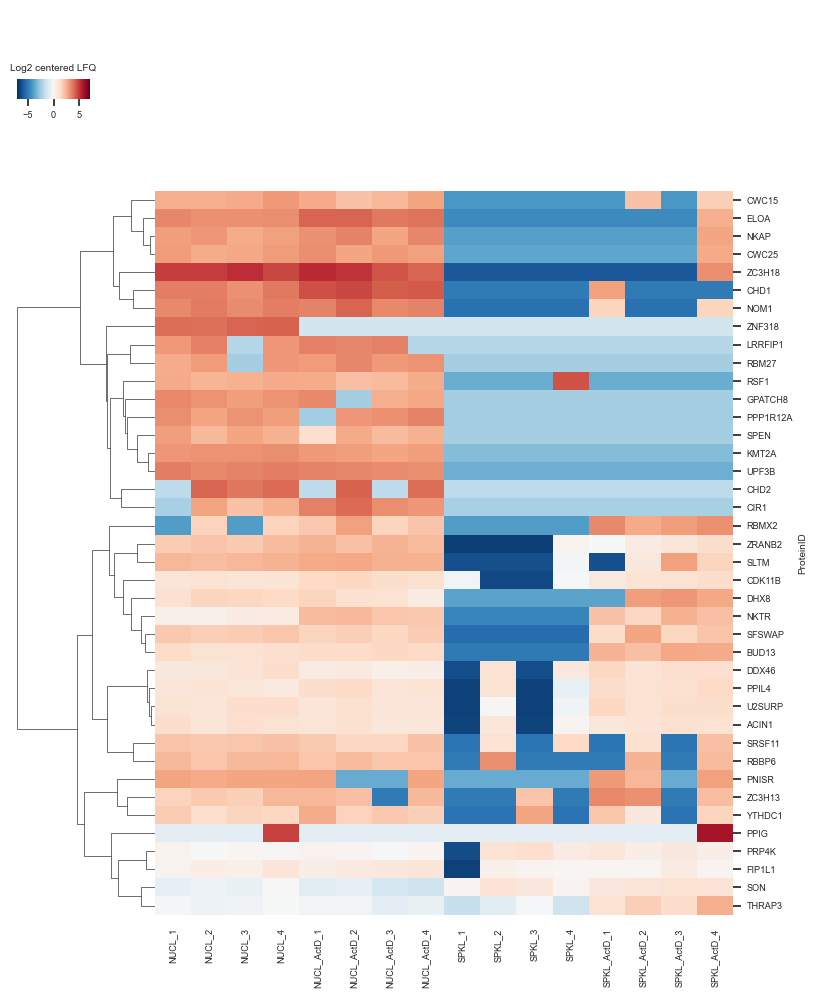

In [13]:
sns.set(font_scale=0.6)
custom_palette = sns.color_palette("RdBu_r", 31, as_cmap=True)
unique_groups = experiment_annotation['condition'].unique()
palette = sns.color_palette("Paired", len(unique_groups))
group_colors = dict(zip(unique_groups, palette))

# Map colors to the DataFrame for column colors
col_colors = experiment_annotation['condition'].map(group_colors)

# Plot the heatmap
heat_clust = sns.clustermap(data_centered,
                            col_cluster=False,
                            yticklabels=row_labels,  # <-- Pass your list of gene names here
                            method='ward',
                            cmap=custom_palette,
                            vmin=-7,
                            center=0,
                            vmax=7,
                            metric='seuclidean',
                            cbar_kws=dict(
                                ticks=[-10, -5, 0, 5, 10],
                                orientation="horizontal",  
                            )
                           )

x0, _y0, _w, _h = heat_clust.cbar_pos
heat_clust.ax_cbar.set_position([x0,
                                 0.9,
                                 heat_clust.ax_row_dendrogram.get_position().width/2,
                                 0.02]
                               )
heat_clust.ax_cbar.set_title('Log2 centered LFQ')
heat_clust.ax_cbar.tick_params(axis='x', length=5)

heat_clust.fig.set_size_inches((8, 10))

heat_clust.savefig("Heatmap_clustered_NPM1_SRRM2__ActD_FANCI.pdf", format='pdf')
heat_clust.savefig("Heatmap_clustered_NPM1_SRRM2__ActD_FANCI.png", format='png', dpi=300)

In [14]:
data_centered.to_csv('data_centered_2.csv', index=True)

In [16]:
DE_results = pd.read_csv("DE_results.csv")

In [17]:
RBPbase_Hs = pd.read_excel("RBPbase_Hs_DescriptiveID.xlsx")

In [18]:
condition_mapping = experiment_annotation['condition'].to_dict()

In [19]:
mean_expr_df = Filtered.T.groupby(condition_mapping).mean().T

In [20]:
mean_expr_df

,NUCL,NUCL_ActD,SPKL,SPKL_ActD
ProteinID,,,,
O14646,17.353243,18.273272,8.922656,10.866785
O14647,13.233207,11.841141,8.922656,8.922656
O14974,14.399951,13.188442,8.922656,8.922656
O15042,16.572368,16.419205,11.127190,16.685077
O95218,17.494072,17.822899,8.922656,16.198231
P18583,15.246262,14.616671,16.269828,16.548617
P21127,16.168067,16.522560,10.949224,16.241821
P30414,14.039191,15.618208,8.922656,15.558781
Q03164,15.110888,14.861646,8.922656,8.922656


In [21]:
RBPbase = RBPbase_Hs[RBPbase_Hs["RBPDB-Hs\nRBPANNO000000023.1"] == "YES"]
RBPbase_v = RBPbase["UnitProtSwissProtID-Hs\nRBPANNO000000043.1"].values

# RBPbase = RBPbase_Hs[RBPbase_Hs["humanRBPs-2021\nRBPANNO000000078.1"] == "YES"]
# RBPbase_v = RBPbase["UnitProtSwissProtID-Hs\nRBPANNO000000043.1"].values

In [22]:
len(RBPbase)

404

In [23]:
RBPbase_v =  [x for x in RBPbase_v if str(x) != 'nan']
len(RBPbase_v)

397

In [24]:
# Load sample annotations
annot_df = pd.read_csv('experiment_annotation.tsv', sep = '\t')

In [25]:
custom_gene_sets = {
    'RBPbase': RBPbase_v,
    'dual_g': dual_g
}

In [26]:
classes = experiment_annotation['condition'].tolist()

In [27]:
# 1. Define the TWO specific groups you want to compare
groups_to_compare = ['SPKL', 'SPKL_ActD']

# 2. Filter your annotation dataframe
annot_filtered = experiment_annotation[experiment_annotation['condition'].isin(groups_to_compare)]

# 3. Extract the sample IDs and the new class list
samples_to_keep = annot_filtered['sample_name'].tolist()
classes_subset = annot_filtered['condition'].tolist()

# 4. Subset the expression matrix to match
expr_df_subset = Filtered[samples_to_keep]

In [29]:
DE_results = pd.read_csv("DE_results.csv")

In [30]:
ranked_genes = DE_results.set_index("Protein ID").sort_values("NSPKL_vs_DMSO_log2 fold change", ascending=False)

In [31]:
ranked_genes = ranked_genes["NSPKL_vs_DMSO_log2 fold change"]

In [32]:
# 3. Run Pre-ranked GSEA
res_prerank = gp.prerank(
    rnk=ranked_genes,
    gene_sets=custom_gene_sets,
    permutation_num=1000,
    threads=12,
    min_size=1,
    max_size=20000,
    outdir='gseapy_prerank_results'
)

2026-11-02 21:39:35,126 [WARNING] Duplicated values found in preranked stats: 20.76% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


In [33]:
# Run standard GSEA
res = gp.gsea(
    data=expr_df_subset,
    gene_sets=custom_gene_sets,
    cls=classes_subset,
    min_size=1,
    permutation_num=1000, 
    outdir='gseapy_results',
    method='signal_to_noise', # Standard ranking metric
    threads=12
)

# View the top results
print(res.res2d.head())

   Name     Term        ES       NES NOM p-val FDR q-val FWER p-val Tag %  \
0  gsea  RBPbase -0.738757 -1.478213  0.146552  0.146552   0.060345  3/12   

   Gene %            Lead_genes  
0  20.69%  Q9Y388;O95218;Q12872  


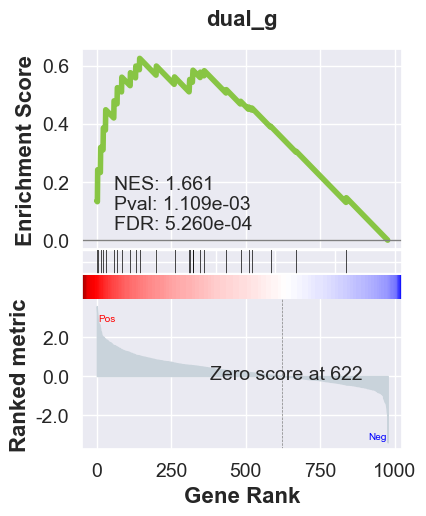

In [34]:
## easy way
terms = res_prerank.res2d.Term
axs = res_prerank.plot(terms=terms[1])
plt.savefig("RBPbase_GSEA.pdf", format="pdf", bbox_inches="tight")

In [35]:
terms

0    RBPbase
1     dual_g
Name: Term, dtype: object

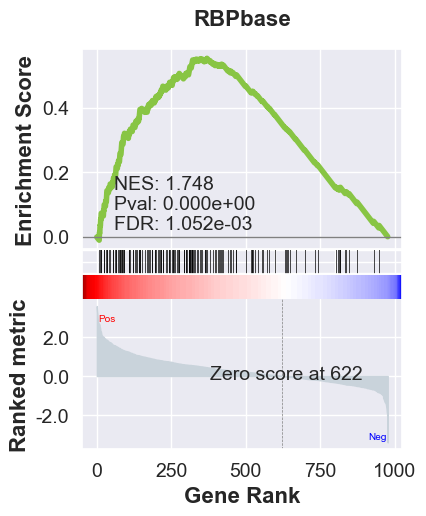

In [36]:
## easy way
# terms = res_prerank.res2d.Term
axs = res_prerank.plot(terms=terms[0])
plt.savefig("Dual_Grammar_GSEA.pdf", format="pdf", bbox_inches="tight")

In [37]:
res_prerank.res2d.Term.iloc[0]

'RBPbase'

In [38]:
# Assuming 'res' is your completed GSEA or Prerank results object
term = res_prerank.res2d.Term.iloc[0]  # Grabbing the top term as an example

my_colors = ["#009688", "#932191"]
custom_cmap = mcolors.LinearSegmentedColormap.from_list("teal_purple", my_colors)

# Plot using a different colormap, like 'viridis'
gp.gseaplot(
    rank_metric=res_prerank.ranking, 
    term=term, 
    **res_prerank.results[term], 
    cmap=custom_cmap,        # <-- Change your colormap here
    ofname='gsea_plot_DualG.pdf' # Optional: output file name
)


# Assuming 'res' is your completed GSEA or Prerank results object
term1 = res_prerank.res2d.Term.iloc[1]  # Grabbing the top term as an example

# Plot using a different colormap, like 'viridis'
gp.gseaplot(
    rank_metric=res_prerank.ranking, 
    term=term1, 
    **res_prerank.results[term1], 
    cmap=custom_cmap,        # <-- Change your colormap here
    ofname='gsea_plot_RBP.pdf' # Optional: output file name
)

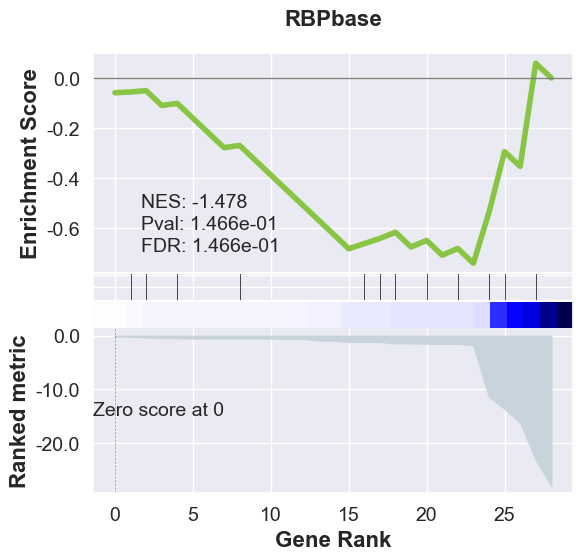

In [39]:
top_pathway = res.res2d['Term'].iloc[0]

# Generate the GSEA plot
fig = gp.plot.gseaplot(
    rank_metric=res.ranking,
    term=top_pathway,
    **res.results[top_pathway] # Unpacks the specific stats for this pathway
)

plt.show()

In [40]:
res.res2d['Term']

0    RBPbase
Name: Term, dtype: object